# Zomato Exploratory Data Analysis Project

## Step - 1  Installing Matplotlib & Seaborn Library

In [3]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


## Step - 2 Importing all required Libraries

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Step - 3 Loading the Dataset

In [11]:
df = pd.read_csv("zomato_data.csv")

In [13]:
df.head()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [15]:
df.shape

(148, 7)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Restaurant Name              148 non-null    object
 1   Online_Order                 148 non-null    object
 2   Book_Table                   148 non-null    object
 3   Rate                         148 non-null    object
 4   Votes                        148 non-null    int64 
 5   Approx_Cost(For Two People)  148 non-null    int64 
 6   Listed_In(Type)              148 non-null    object
dtypes: int64(2), object(5)
memory usage: 8.2+ KB


In [19]:
df.describe()

,Votes,Approx_Cost(For Two People)
count,148.000000,148.000000
mean,264.810811,418.243243
std,653.676951,223.085098
min,0.000000,100.000000
25%,6.750000,200.000000
50%,43.500000,400.000000
75%,221.750000,600.000000
max,4884.000000,950.000000


In [21]:
df.describe(include = "all")

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
count,148,148,148,148,148.000000,148.000000,148
unique,145,2,2,20,NaN,NaN,4
top,San Churro Cafe,No,No,3.8/5,NaN,NaN,Dining
freq,2,90,140,19,NaN,NaN,110
mean,NaN,NaN,NaN,NaN,264.810811,418.243243,NaN
std,NaN,NaN,NaN,NaN,653.676951,223.085098,NaN
min,NaN,NaN,NaN,NaN,0.000000,100.000000,NaN
25%,NaN,NaN,NaN,NaN,6.750000,200.000000,NaN
50%,NaN,NaN,NaN,NaN,43.500000,400.000000,NaN
75%,NaN,NaN,NaN,NaN,221.750000,600.000000,NaN


## Step - 4 Data Cleaning & Preparation

### Convert the Rate Column to a Numeric Data type

In [25]:
def handleRate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)
df['Rate'] = df['Rate'].apply(handleRate)
print(df.head(5))

         Restaurant Name Online_Order Book_Table  Rate  Votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   Approx_Cost(For Two People) Listed_In(Type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Restaurant Name              148 non-null    object 
 1   Online_Order                 148 non-null    object 
 2   Book_Table                   148 non-null    object 
 3   Rate                         148 non-null    float64
 4   Votes                        148 non-null    int64  
 5   Approx_Cost(For Two People)  148 non-null    int64  
 6   Listed_In(Type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


### Standardize Column Names

In [30]:
df.columns = df.columns.str.lower()

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant name              148 non-null    object 
 1   online_order                 148 non-null    object 
 2   book_table                   148 non-null    object 
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    object 
dtypes: float64(1), int64(2), object(4)
memory usage: 8.2+ KB


In [34]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='object')

### Rename the Cost Column

In [49]:
df.rename(
    columns = {'approx_cost(for two people)':'approx_cost'},
    inplace = True
)

In [51]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost', 'listed_in(type)'],
      dtype='object')

### Checking for Missing Values & Duplicate Records

In [61]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicate Rows:", df.duplicated().sum())

Missing values:
restaurant name    0
online_order       0
book_table         0
rate               0
votes              0
approx_cost        0
listed_in(type)    0
dtype: int64
Duplicate Rows: 0


## Step - 5 Exploratory Data Analysis

## 1. How many customer votes has each restaurant type received?

In [77]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [79]:
grouped_data = df.groupby('listed_in(type)')['votes'].sum()
grouped_data

listed_in(type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: votes, dtype: int64

## 2. How many restaurants offer table booking?

In [81]:
result = df['book_table'].value_counts()
result

book_table
No     140
Yes      8
Name: count, dtype: int64

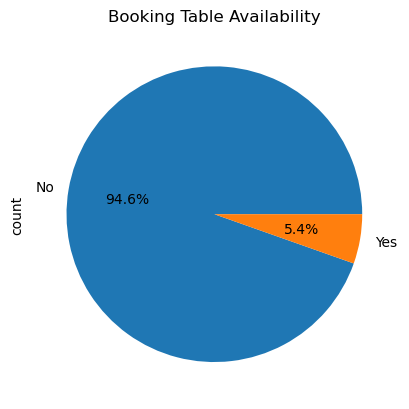

In [91]:
result.plot.pie(autopct = "%1.1f%%")
plt.title("Booking Table Availability")
plt.show()

## 3. Which five restaurants have the highest number of votes?

In [93]:
top5 = df.nlargest(5,'votes')
print(top5[["restaurant name","votes"]])

      restaurant name  votes
38  Empire Restaurant   4884
86      Meghana Foods   4401
7              Onesta   2556
44             Onesta   2556
65        Kabab Magic   1720


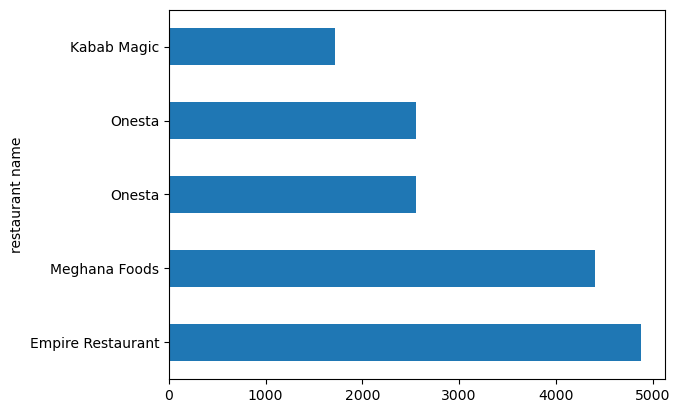

In [95]:
top5.plot.barh(x = 'restaurant name', y = 'votes', legend = False)
plt.show()

## 4. Is there a relationship between restaurant ratings and customer votes?

In [97]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


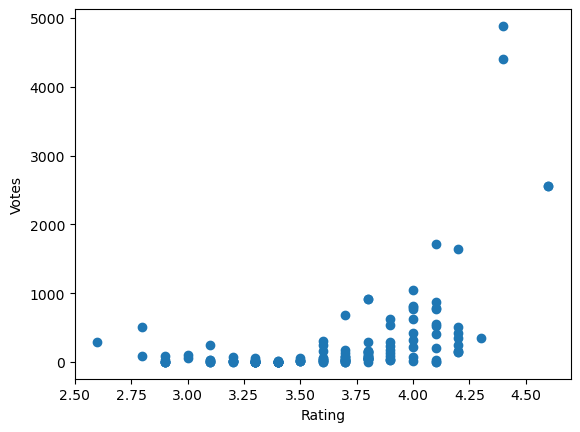

In [99]:
plt.scatter(df["rate"],df["votes"])
plt.xlabel("Rating")
plt.ylabel("Votes")
plt.show()

## 5. What is the average rating for each restaurant type?

In [101]:
result = df.groupby('listed_in(type)')['rate'].mean()
result

listed_in(type)
Buffet    3.842857
Cafes     3.765217
Dining    3.571818
other     3.912500
Name: rate, dtype: float64

In [105]:
print(result.sort_values(ascending = False))

listed_in(type)
other     3.912500
Buffet    3.842857
Cafes     3.765217
Dining    3.571818
Name: rate, dtype: float64


## 6. What type of restaurant do the majority of customers order from?

Text(0, 0.5, 'Count of Restaurant')

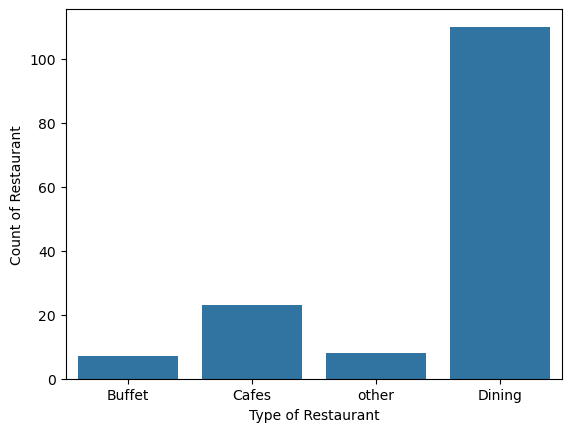

In [107]:
sns.countplot(x = df['listed_in(type)'])
plt.xlabel("Type of Restaurant")
plt.ylabel("Count of Restaurant")

## 7. What ratings do restaurants most commonly receive?

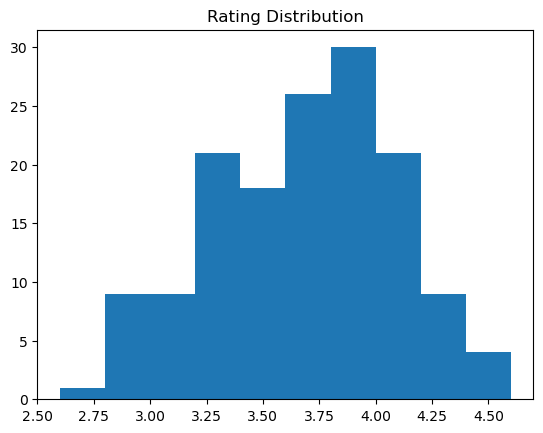

In [109]:
plt.hist(df['rate'], bins = 10)
plt.title("Rating Distribution")
plt.show()

## 8. Which restaurant type has the highest average cost for two people?

In [111]:
result = df.groupby('listed_in(type)')['approx_cost'].mean()
result.sort_values(ascending = False)

listed_in(type)
Buffet    671.428571
other     668.750000
Cafes     545.652174
Dining    357.272727
Name: approx_cost, dtype: float64

## 9. Which order mode — online or offline — gets better ratings?

In [113]:
df.head()

,restaurant name,online_order,book_table,rate,votes,approx_cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


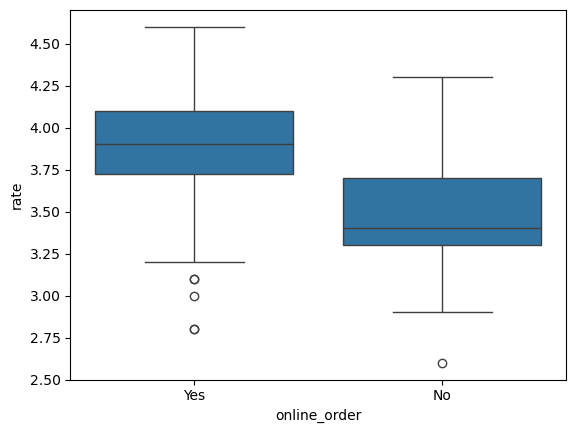

In [115]:
sns.boxplot(x = 'online_order', y = 'rate', data = df)
plt.show()

## 10. Which restaurant types have more offline-ordering records?

In [119]:
pivot_table = df.pivot_table(
    index = 'listed_in(type)',
    columns = 'online_order',
    aggfunc = 'size',
    fill_value = 0
)
pivot_table

online_order,No,Yes
listed_in(type),,
Buffet,3,4
Cafes,8,15
Dining,77,33
other,2,6


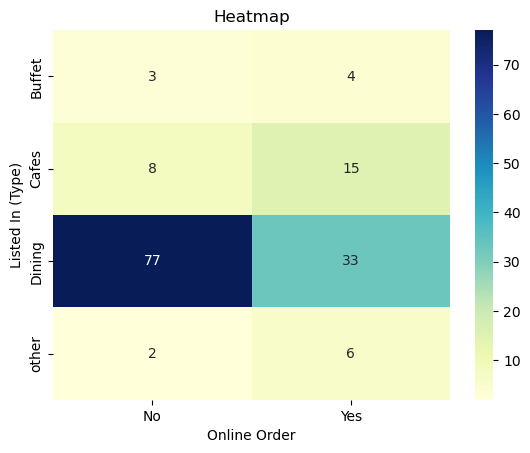

In [121]:
sns.heatmap(
    pivot_table, annot = True, cmap = "YlGnBu", fmt = 'd')
plt.title("Heatmap")
plt.xlabel("Online Order")
plt.ylabel("Listed In (Type)")
plt.show()